# Introduction to Data Visualization

Data visualization is an essential part of data analysis and data science. It provides a visual representation of data, making it easier to explore datasets, identify patterns, detect outliers, and discover relationships between variables.

While statistical methods help us quantify patterns and test hypotheses, visualizations allow us to gain an intuitive understanding of the data and communicate our findings effectively. A well-chosen plot can often reveal information that is difficult to recognize by looking at tables of numbers alone.

In Python, two widely used libraries for data visualization are Matplotlib and Seaborn. Besides dedicated visualization libraries, Pandas also provides built-in plotting functionality. Since Pandas is primarily used for data manipulation and analysis, it offers convenient methods for creating basic visualizations directly from Series and DataFrames. Pandas plotting methods are built on top of Matplotlib, meaning that they use Matplotlib in the background. This makes it possible to quickly explore data without having to write much plotting code, while still allowing further customization using Matplotlib.

Throughout this notebook, we will use all three approaches.

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import os

In [2]:
os.chdir("..\\data")

## Matplotlib

`matplotlib` is a main Python library for static, animated, and interactive visualizations. It is designed with the philosophy that you should be able to create simple plots with just a few commands. A large number of third party packages extend and build on Matplotlib functionality.

We won't using whole `matplotlib`, but just its module pyplot, whose common alias is `plt`. Each pyplot function makes some change to a figure: e.g., creates a figure, creates a plotting area in a figure, plots some lines in a plotting area, decorates the plot with labels, etc.

<div class="alert alert-block alert-warning">
<b>Example: </b> For warming up, let's plot a sine function on $[-\pi, \pi]$ interval. We will pass 256 points from the interval $[-\pi, \pi]$ and their function values to the `plt.plot()` function, which will plot a line graph for us. To display all open figures with matplotlib, use `plt.show()`.
</div>

In [ ]:
X = np.linspace(-np.pi, np.pi, 256, endpoint=True)
S = np.sin(X)

plt.plot(X, S)
plt.show() # Display a figure

If we call `plt.plot()` multiple times, matplotlib will plot line graphs on the same figure and even do some customization for you (notice colors in the following example):

In [ ]:
X = np.linspace(-np.pi, np.pi, 256, endpoint=True)
C, S = np.cos(X), np.sin(X)

plt.plot(X, C)
plt.plot(X, S)
plt.show() # Display a figure

To save a plot as an image use `plt.savefig()` function.You can save plots in various formats (PNG, JPEG, SVG, PDF etc.). The desired format is determined by the file extension specified in the filename (the first argument of `plt.savefig()`). If you want to both save the plot and display it in a window, call `plt.savefig()` before `plt.show()`. You can also control the image resolution using the `dpi` (dots per inch) parameter.

<div class="alert alert-block alert-success">
<b>Task: </b>Save and show previous plot according to the above instructions. Use file format by choice and 100 dpi. Try to enlarge <code>dpi</code> parameter and open saved plot image. What you can notice?
</div>

In [ ]:
#solution

## Customizing matplotlib

To customize matplotlib plots, first we need to understand main parts of matplotlib plot:

![labels_matplotlib.png](../imgs/labels_matplotlib.png)

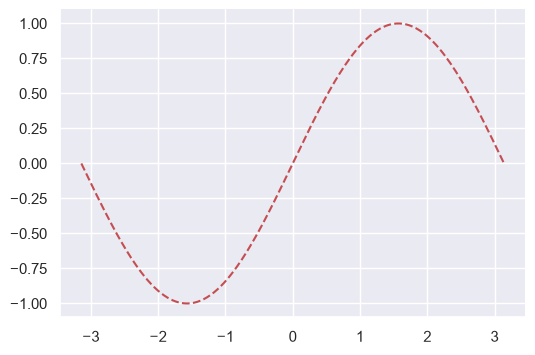

In [192]:
fig = plt.figure(figsize=(6,4))
ax = fig.add_subplot()

X = np.linspace(-np.pi, np.pi, 256, endpoint=True)
S = np.sin(X)

ax.plot(X, S, 'r--')

# Hide individual spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.show()

## Working with multiple figures and axes

Multiple Axes are placed in a regular grid in the Matplotlib Figure. Another term that is often used is "subplot", which refers to an Axes that is in a grid with other Axes objects.

![multiple.png](../imgs/multiple.png)

There are multiple ways for creating such grid in the Matplolib, but we will show the simplest and the most common one:
Grid-shaped combinations of Axes (recommended):
>- Create the Axes together with the Figure<br>
    >`fig, ax = plt.subplots()  # a figure with a single Axes`<br>
    OR<br>
    >`fig, axs = plt.subplots(2, 2)  # a figure with a 2x2 grid of Axes`<br>
>- Add plots to the certain Axes:<br>
    >`ax.plot()` # single Axes<br>
    OR<br>
    >`axs[0].plot()` # for example, on the first Axes<br>

<div class="alert alert-block alert-warning">
<b>Example: </b>Plot below functions as two plots in the same figure:
    <p>$f_1(x) = e^{-x} \cos{2 \pi x}$</p>
    <p>$f_2(x) = \cos{2 \pi x}$</p>
</div>

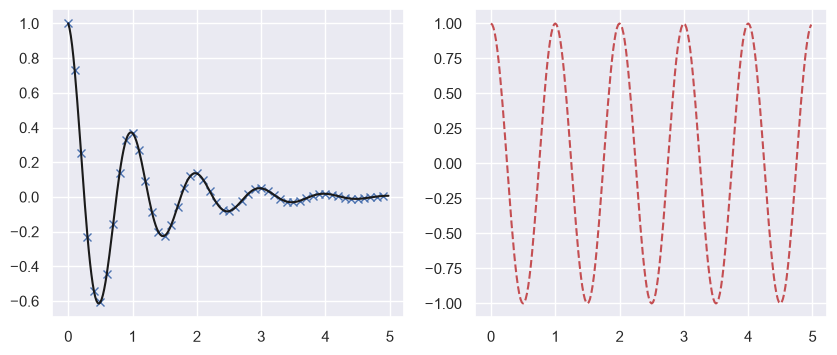

In [193]:
def f(t):
    return np.exp(-t) * np.cos(2*np.pi*t)

t1 = np.arange(0.0, 5.0, 0.1)
t2 = np.arange(0.0, 5.0, 0.02)

fig, axs = plt.subplots(1, 2, figsize=(10, 4)) # 1 is the figure number

# First axes
axs[0].plot(t1, f(t1), 'bx', t2, f(t2), 'k')

# Second axes
axs[1].plot(t2, np.cos(2*np.pi*t2), 'r--')

axs[0].grid(True)
plt.show()

## Seaborn

Seaborn is a Python library for statistical data visualization, built on top of Matplotlib. It provides a high-level interface for creating attractive and informative statistical graphics with minimal code. Seaborn comes with a variety of built-in themes and color palettes that make visualizations more appealing and easier to interpret. It is also closely integrated with Pandas, allowing users to work directly with DataFrames and Series when creating plots.

Plot style can be set with `seaborn.set_style()`. The style parameters control properties like the color of the background and whether a grid is enabled by default. For example:
>sns.set_style("whitegrid")

The  `set_context() ` function provides a useful way to control some of the elements of the plot without changing its overall style. For example:
>sns.set_context(rc={"figure.figsize": (10, 10)})

<div class="alert alert-block alert-info">
<b>Tip: </b>Be aware that some seaborn visualizations are <a href="https://seaborn.pydata.org/tutorial/function_overview.html#figure-level-vs-axes-level-functions">figure-level and some axes-level</a>. Each module has a single figure-level function, which offers a unitary interface to its various axes-level functions. The organization is given in the figure below.
</div>


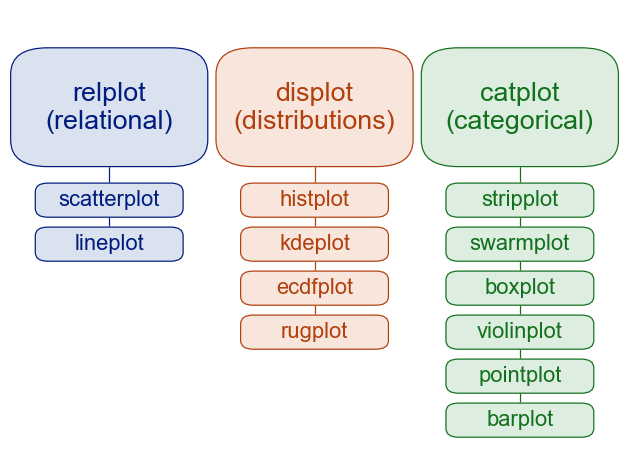

In [4]:
sns.set_theme()

# Data import

**Dataset description**:
Throughout this notebook, we will use the [Bike Sharing](http://capitalbikeshare.com/system-data) dataset, which contains information about daily bike rentals in Washington, D.C., during 2011 and 2012. In addition to the number of rented bikes, the dataset includes information about weather conditions, temperature, humidity, seasons, and calendar characteristics. Bike-sharing rental process is highly correlated to the environmental and seasonal settings.

Our goal is to explore this dataset using different data visualization techniques. By working with the same dataset throughout the notebook, we can approach it from different analytical perspectives and understand how the choice of visualization helps reveal different patterns and characteristics of the data.

Reference: [Fanaee-T & Joao, Event labeling combining ensemble detectors and background knowledge, Progress in Artificial Intelligence (2013), pp. 1-15, Springer Berlin Heidelberg](https://link.springer.com/article/10.1007/s13748-013-0040-3)

In [212]:
data = pd.read_csv('day.csv')
data.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


Check data types and missing values

In [213]:
data.dtypes

instant         int64
dteday            str
season          int64
yr              int64
mnth            int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object

In [223]:
data.isnull().any()

instant       False
dteday        False
season        False
yr            False
mnth          False
holiday       False
weekday       False
workingday    False
weathersit    False
temp          False
atemp         False
hum           False
windspeed     False
casual        False
registered    False
cnt           False
dtype: bool

For easier manipulation with dates, convert date string to date format:

In [214]:
data['dteday'] = pd.to_datetime(data['dteday'], format='mixed')

# Trend Analysis

Line plots are particularly useful when working with time-dependent data because they connect consecutive observations, making it easier to recognize patterns and changes over time.

<div class="alert alert-block alert-warning">
<b>Example: </b>
    
1. Visualize bike rentals for 2011.
2. Compare the number of bike rentals between the two years.
</div>

First, filter the dataset to include only observations from 2011.

In [216]:
plot_data = data[data['yr'] == 0]
plot_data.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


### Solution 1: Matplotlib

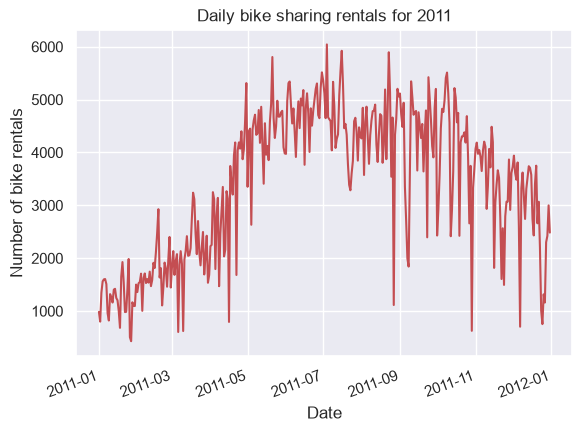

In [230]:
#Task 1
fig, ax = plt.subplots()

ax.plot(plot_data['dteday'], plot_data['cnt'],'r')

# Customize
ax.grid(True) # for grid lines (both vertical and horizontal)
fig.autofmt_xdate(rotation=20) # to rotate dates on x-axis
ax.set_xlabel('Date')
ax.set_ylabel('Number of bike rentals')
ax.set_title('Daily bike sharing rentals for 2011')

plt.show()

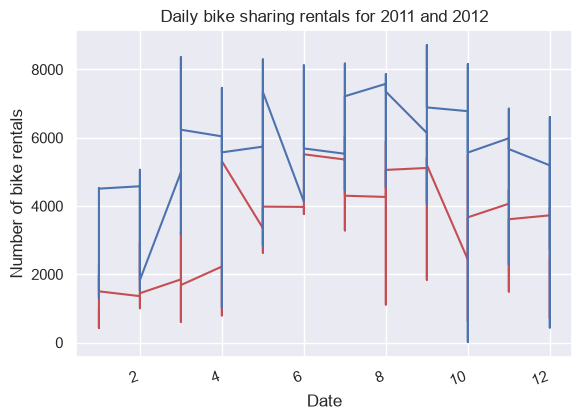

In [224]:
#Task 2
fig, ax = plt.subplots()

colors = ['r', 'b', 'g']
for i, (y, df) in enumerate(data.groupby('yr')):
    ax.plot(df['mnth'], df['cnt'],f'{colors[i]}')

# Customize
ax.grid(True) # for grid lines (both vertical and horizontal)
fig.autofmt_xdate(rotation=20) # to rotate dates on x-axis
ax.set_xlabel('Date')
ax.set_ylabel('Number of bike rentals')
ax.set_title('Daily bike sharing rentals for 2011 and 2012')

plt.show()

### Solution 2: Pandas plot

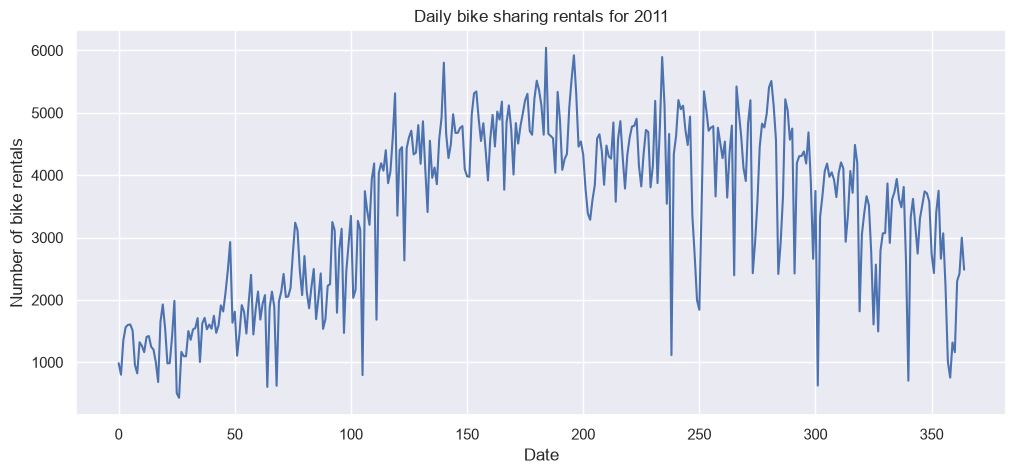

In [231]:
#Task 1
plot_data['cnt'].plot.line(figsize=(12, 5), title='Daily bike sharing rentals for 2011', xlabel='Date', ylabel='Number of bike rentals',
                             grid=True)
plt.show()

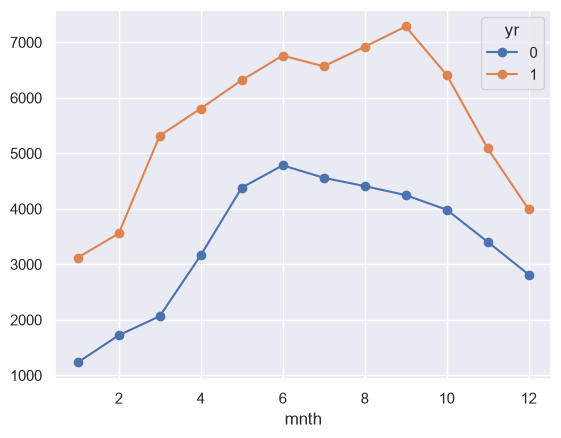

In [227]:
#Task 2
pivot_df = data.pivot_table(index="mnth", columns='yr', values="cnt")
pivot_df.plot.line(marker='o')
plt.show()

### Solution 3: Seaborn

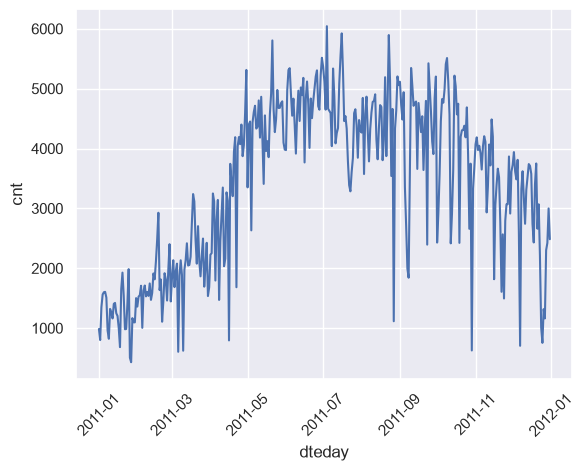

In [232]:
# Task 1
ax = sns.lineplot(x='dteday', y='cnt', data=plot_data)
ax.tick_params(axis='x', labelrotation=45) # Matplotlib: to rotate dates on x-axis
plt.show()

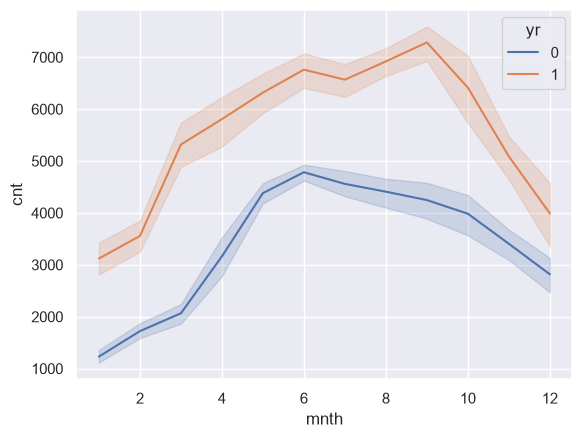

In [235]:
# Task 2
ax = sns.lineplot(x='mnth', y='cnt', hue='yr', data=data) # notice hue; color years differently
plt.show()

# Relationship Analysis

Relationship analysis focuses on exploring how two numerical variables are associated with each other. By visualizing their relationship, we can identify patterns, trends, correlations, and potential outliers, helping us better understand how changes in one variable relate to changes in another.

Two commonly used visualizations for this purpose are:
 - scatterplots - observations as points (`plt.scatter` or `sns.scatterplots`)
 - regression plots - extend scatterplots by adding a fitted regression line (`sns.regplot`).

*Keep in mind*: A visible relationship between two variables does not necessarily imply causation. Scatterplots and regression lines help us explore associations, but they do not establish cause-and-effect relationships.

<div class="alert alert-block alert-warning">
<b>Example: </b>Investigate whether temperature is associated with the number of daily bike rentals. Do warmer days tend to have higher rental counts?
Are there any unusual observations or potential outliers?
</div>

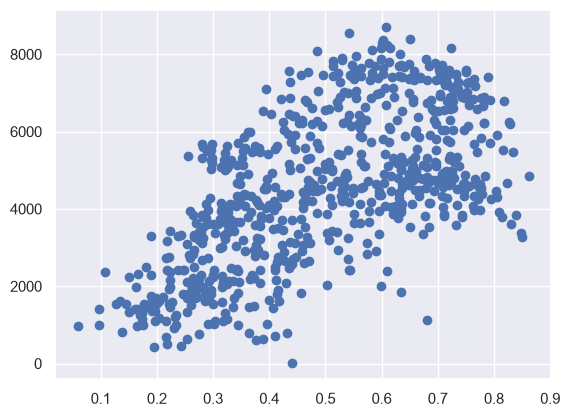

In [236]:
#Solution 1: Matplotlib 
fig, ax = plt.subplots()
ax.scatter(data['temp'], data['cnt'])
plt.show()

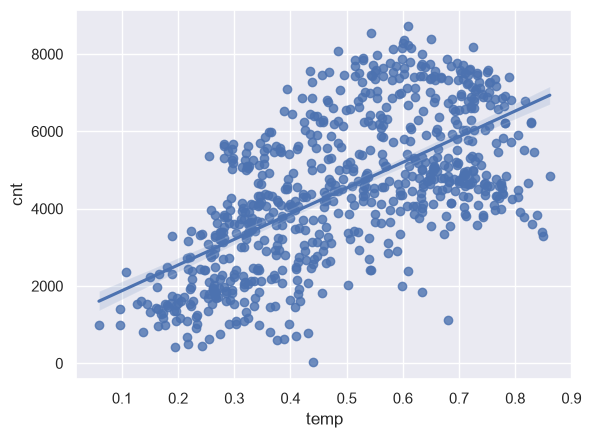

In [237]:
#Solution 2: Seaborn
sns.regplot(x='temp', y='cnt', data=data)
plt.show()

# Categorical Data Analysis

Visualizing categorical data helps us understand how observations are distributed among categories, compare values across groups, and identify differences or patterns between them.

In Seaborn library,  and `sns.barplot()` both use bars to represent data, but they serve different analytical purposes:
Common visualizations for categorical data include:

1. Count plots: Display the number of observations in each category, making it easy to compare category frequencies (use `plt.bar()` or `sns.countplot()`).
2. Bar plots: Show aggregated numerical values (such as mean, median, or sum) for different categories (use `plt.bar()` or `sns.barplot()`).
3. Grouped and stacked bar plots: Allow comparisons between multiple groups or show how subcategories contribute to each category.

<div class="alert alert-block alert-warning">
<b>Example: </b>Use a count plot to explore the number of observations on working and non-working days
</div>

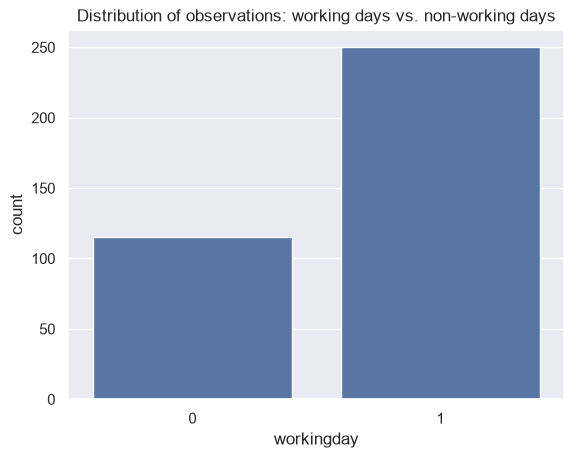

In [248]:
ax = sns.countplot(x='workingday', data=plot_data) 
ax.set_title('Distribution of observations: working days vs. non-working days')
plt.show()

<div class="alert alert-block alert-warning">
<b>Example: </b>Use a count plot to explore how the number of observations is distributed across seasons and working days. Can you identify any differences in the distribution of working days and non-working days?
</div>

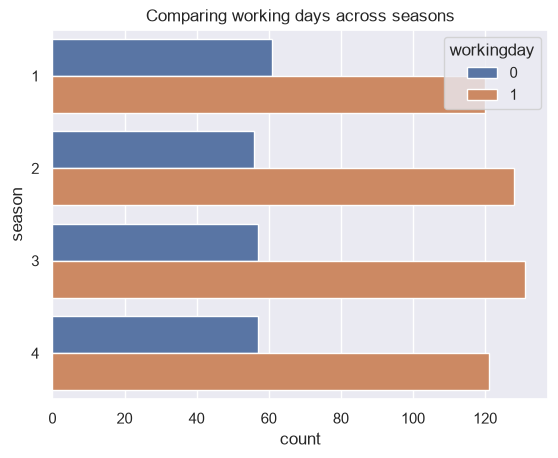

In [246]:
#3. solution 
sns.countplot(y='season', hue='workingday', data=data)
plt.title('Comparing working days across seasons')
plt.show()

<div class="alert alert-block alert-success">
<b>Task: </b>Repeat the visualization using <i>weathersit</i> on the x-axis and <i>season</i> as the hue variable. Explore how weather conditions are distributed across seasons.
</div>

In [ ]:
#solution

<div class="alert alert-block alert-warning">
<b>Example: </b>In this example, we use a bar plot to compare the average number of bike rentals between working days and non-working days. Is the average number of bike rentals higher on working days or non-working days?
</div>

Note: The bars represent average daily rental counts, not the total number of rentals across all working or non-working days. Seaborn also displays confidence intervals by default.

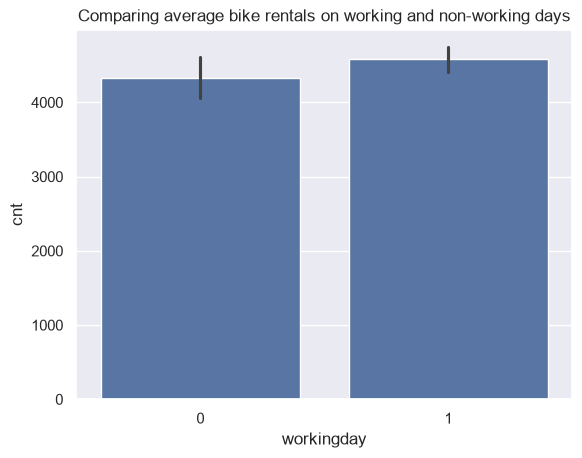

In [253]:
ax = sns.barplot(x='workingday', y='cnt', data=data);
plt.title('Comparing average bike rentals on working and non-working days')
plt.show()

# Univariate and Grouped Distribution Analysis

Before we look at relationships between variables, we need to understand each variable on its own. Univariate analysis examines one variable at a time and answers basic questions: What values does it take? Where is the center? How spread out is it? Is the distribution symmetric or skewed? Are there outliers, gaps, or several peaks (modes)?

The choice of plot depends on the type of variable:
- Numerical variables: histogram, KDE plot, boxplot, violin plot.
- Categorical variables: count plot or bar plot.

A single distribution computed over the whole dataset can be misleading, because the dataset often mixes several subpopulations. In the Bike Sharing data, for instance, rentals on a winter workday and on a summer weekend are very different situations. Grouped distribution analysis addresses this by splitting a numerical variable according to a categorical one (e.g., cnt by season, yr, or workingday) and comparing the resulting distributions side by side. Differences in center, spread, or shape between groups are the first hint that the categorical variable is related to the numerical one.

<div class="alert alert-block alert-warning">
<b>Example: </b>In this example, we use a histogram combined with a Kernel Density Estimate (KDE) curve to explore the distribution of daily bike rentals (cnt) across 2011 and 2012. The histogram displays the frequency of daily rental counts within different intervals, while the KDE curve provides a smoothed representation of the distribution.

Observe the visualization and consider the following questions:
1. Which rental count intervals occur most frequently?
2. Is the distribution symmetric or skewed?
3. Are there any unusually high or low daily rental counts?
</div>

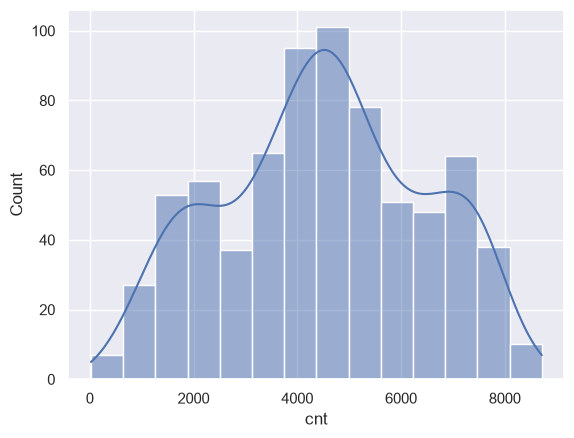

In [279]:
ax = sns.histplot(data=data, x='cnt', kde=True) # two plots in single visualization, sns.histplot() + sns.kdeplot()
ax.set_title('Distribution of daily bike rentals for 2011 and 2012')
plt.show()

<div class="alert alert-block alert-warning">
<b>Example: </b>In this example, we use a joint plot to simultaneously explore the relationship between temperature (temp) and the total number of daily bike rentals (cnt).
</div>

`sns.jointplot()` combines a bivariate plot in the center with the univariate marginal distributions on the top and right. With <code>kind="kde"</code>, the central plot shows a two-dimensional density: darker, more concentrated regions are where the most observations lie, and the contour lines connect points of equal density. This works better than a scatter plot when many points overlap.

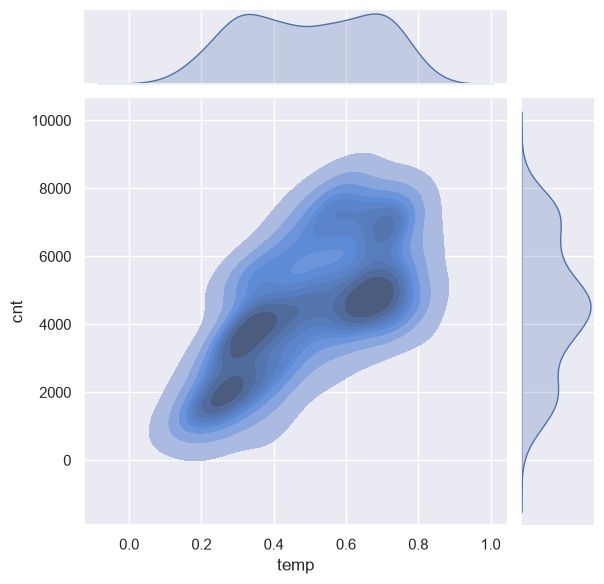

In [278]:
sns.jointplot(data=data, x='temp', y='cnt', kind="kde", fill=True)
plt.show()

<div class="alert alert-block alert-warning">
<b>Example: </b>
Create a boxplot to compare the distribution of daily bike rentals (cnt) between 2011 and 2012. Based on the visualization, determine which year had a higher median number of daily rentals and whether the variability in rental counts changed between the two years.
</div>

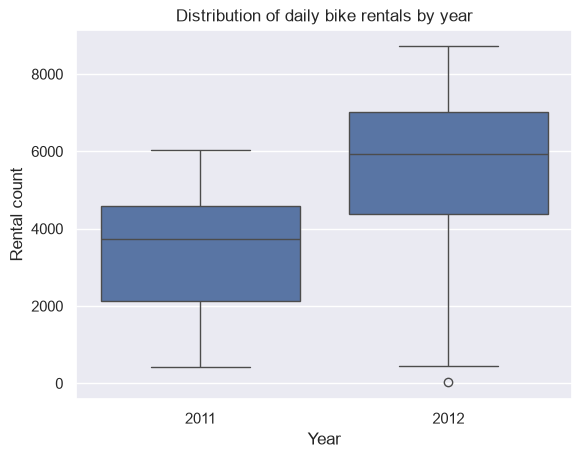

In [273]:
ax = sns.boxplot(data=data, x='yr', y='cnt')
ax.set_xticks([0, 1])
ax.set_xticklabels([2011, 2012])
ax.set_xlabel('Year')
ax.set_ylabel('Rental count')
ax.set_title('Distribution of daily bike rentals by year')
plt.show()

<div class="alert alert-block alert-warning">
<b>Example: </b>
Create a boxplot that compares daily bike rental distributions across both years and working-day categories. Are rental counts more variable on working days or non-working days?
</div>

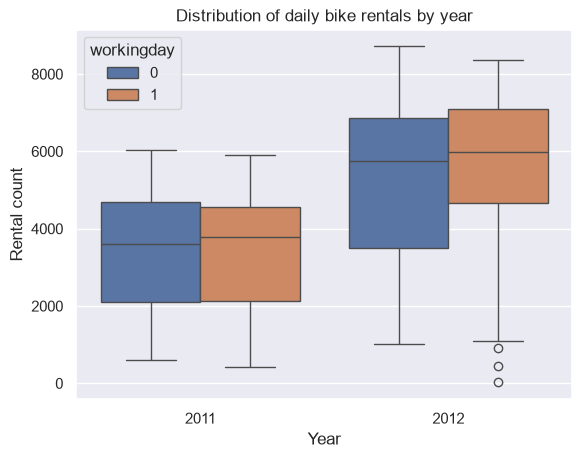

In [275]:
ax = sns.boxplot(data=data, x='yr', y='cnt', hue='workingday')
ax.set_xticks([0, 1])
ax.set_xticklabels([2011, 2012])
ax.set_xlabel('Year')
ax.set_ylabel('Rental count')
ax.set_title('Distribution of daily bike rentals by year')
plt.show()

# Multivariate Analysis and Visualization

Multivariate analysis focuses on exploring relationships and patterns involving three or more variables simultaneously. While visualizations such as scatterplots and boxplots are useful for examining individual variables or relationships between two variables, multivariate visualizations allow us to investigate how several variables interact and how these interactions may reveal more complex patterns in a dataset.

Common techniques for multivariate visualization include:
- Correlation heatmaps: Display correlation coefficients between numerical variables, helping identify strong positive and negative relationships.
- Pair plots: Show pairwise relationships between multiple numerical variables, combining scatterplots and distribution plots.
- Grouped visualizations: Use colors, sizes, or other visual properties to represent additional variables within a plot.

In this section, we will explore how to visualize multiple variables simultaneously using Seaborn.

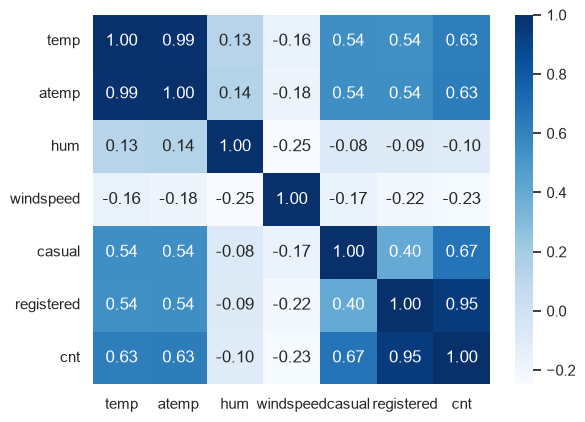

In [284]:
corr = data.iloc[:, 9:].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues')
plt.show()

<div class="alert alert-block alert-success">
<b>Task: </b>

1. Compare casual and registered rentals over time using line plots.
2. Explore whether casual users rent more bikes during weekends.
3. Investigate whether registered users have higher rental activity on working days.
4. Compare how weather conditions affect casual and registered rentals.
</div>

In [ ]:
#solution